# McGill COMP551, MINI-PROJECT 3: Odd-One-Out Image Groups
Student names (IDs) - **Kaggle team name: Group63**



David Xu

Douglas Song

Fredrik Lundquist

Number of model parameters: **24,901**

Public Kaggle leaderboard score： **76.10%**

# Kaggle Competition
Training and test data are available as part of the assignment in the `datasets` folder. To participate in the competition you should upload a CSV file containing your predicted labels for the entire test data to Kaggle.

The test data is divided in half. You receive the correct labels for the first half (in the `datasets` folder), so that you can evaluate your model in this notebook on that part of the test set. You then submit your solution for the entire test set to Kaggle. The final evaluation is based on your predictions for the second half of the test set (private leaderboard). We have step-by-step explanation in the final section of this notebook.


# Report
The purpose of this notebook is for you to provide a concise high level code of your methodology. That is, you need to include all steps necessary to reproduce your results. Please include a high-level explanation of the implementation so that we can understand what you're trying to achieve in each piece of the code. You can import python code here if needed, in order to keep the notebook concise.

**Note:** You need to submit this notebook where you have run all the cells as part of the assignment. **We should not need to rerun your code since this can take a long time.**


## Step 1 — The Dataset
Use the following code to load the data using the npy files. We have **3,000 training examples**, where each example is a group of **5 grayscale images** (each 32×32). In each group:
- **4 images** share a hidden common property, and
- **1 image** is the **outlier**.

You do **not** have access to the underlying attributes. Your task is to learn to identify the **index** of the outlier image (a 5-class classification problem, with labels in {0, 1, 2, 3, 4}). The label is printed above each group shown below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATASET_DIR = '/content/drive/MyDrive/P3_dataset'

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
"""
x = np.load('datasets/x_train.npy')  # (3000, 5, 32, 32) — 3000 groups of 5 images each
y = np.load('datasets/y_train.npy')  # (3000,) — index of the outlier image in each group (0-4)
"""
x = np.load(f'{DATASET_DIR}/x_train.npy')
y = np.load(f'{DATASET_DIR}/y_train.npy')

print(f'Training set: {x.shape[0]} groups, each with {x.shape[1]} images of size {x.shape[2]}x{x.shape[3]}')
print(f'Labels: values in {np.unique(y)}')

Training set: 3000 groups, each with 5 images of size 32x32
Labels: values in [0 1 2 3 4]


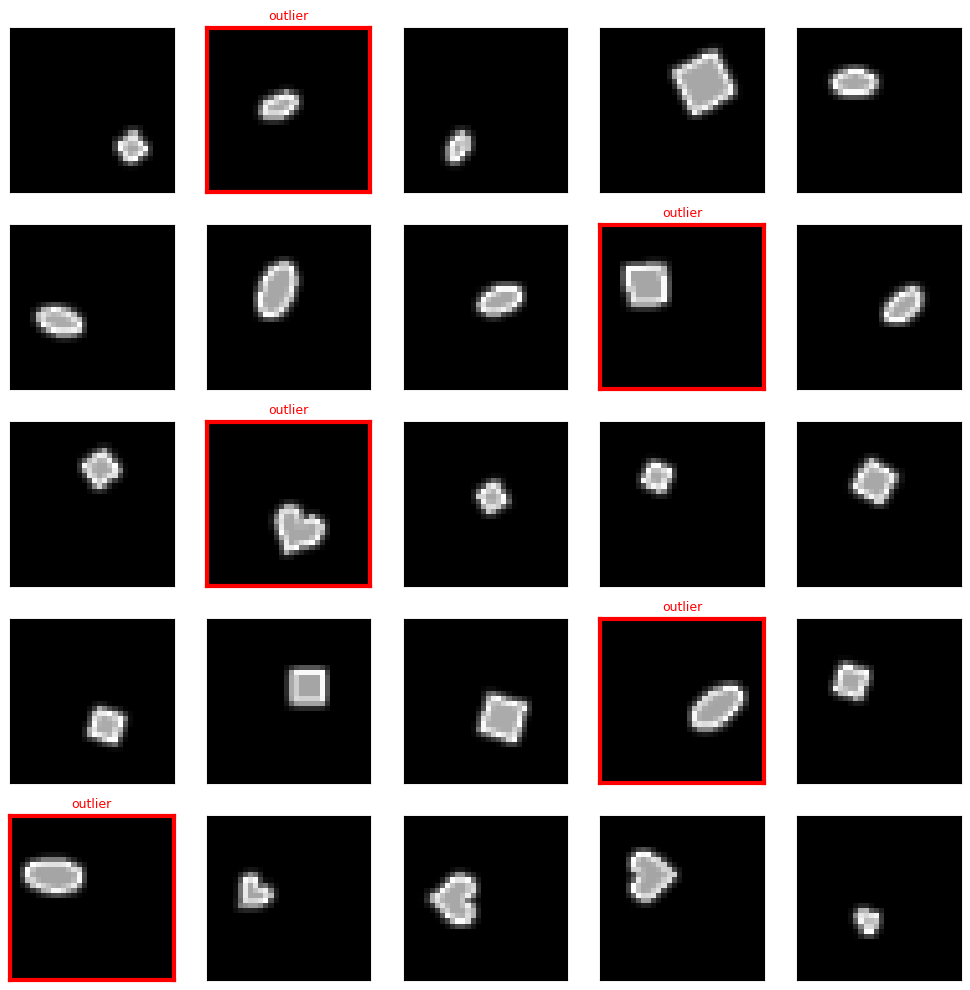

In [ ]:
def plot_groups(x, y, num_groups=5):
    """Plot groups of 5 images. The outlier is highlighted with a red border."""
    fig, axes = plt.subplots(num_groups, 5, figsize=(10, 2 * num_groups))
    for i in range(num_groups):
        for j in range(5):
            axes[i, j].imshow(x[i, j], cmap='gray')
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if j == y[i]:
                for spine in axes[i, j].spines.values():
                    spine.set_edgecolor('red')
                    spine.set_linewidth(3)
                axes[i, j].set_title('outlier', color='red', fontsize=9)
    plt.tight_layout()
    plt.show()

plot_groups(x, y, num_groups=5)

## Step 2 — Example: Logistic Regression Baseline
Below we apply a simple logistic regression to the flattened input as a demonstration. This model treats the entire group of 5 images as one flat vector and does not use any deep learning.

Note that **random chance** for this 5-class problem is **20%** (1/5).
As you can see, the logistic regression baseline performs close to random chance — you are expected to do significantly better using a deep learning model implemented in PyTorch (or Jax/TensorFlow).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

features = x.reshape(x.shape[0], -1)  # flatten each group of 5 images into a single vector
labels = y

x_train, x_val, y_train, y_val = train_test_split(features, labels, test_size=0.33, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(x_train, y_train)

predictions = clf.predict(x_val)
accuracy = accuracy_score(y_val, predictions)
print(f'The validation accuracy of the baseline model is {accuracy * 100:.2f}%')

The validation accuracy of the baseline model is 19.39%


##Step 2.5 Data preprocessing, train/validation split, and PyTorch data pipeline:

In [ ]:
#Imports
import copy
import math
import random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from scipy.ndimage import affine_transform, shift
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings


In [ ]:
# Seed and devices:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
# Load all arrays for deep-learning pipeline:
"""
x_train_full = np.load("datasets/x_train.npy") # (3000, 5, 32, 32)
y_train_full = np.load("datasets/y_train.npy") # (3000,)
x_test = np.load("datasets/x_test.npy")        # (2000, 5, 32, 32)
y_test_half = np.load("datasets/y_test.npy")   # (1000,)
"""
x_train_full = np.load(f"{DATASET_DIR}/x_train.npy")
y_train_full = np.load(f"{DATASET_DIR}/y_train.npy")
x_test = np.load(f"{DATASET_DIR}/x_test.npy")
y_test_half = np.load(f"{DATASET_DIR}/y_test.npy")

print("x_train_full shape:", x_train_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("x_test shape:", x_test.shape)
print("y_test_half shape:", y_test_half.shape)

x_train_full shape: (3000, 5, 32, 32)
y_train_full shape: (3000,)
x_test shape: (2000, 5, 32, 32)
y_test_half shape: (1000,)


In [ ]:
# Train/validation split
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

print("Train split:", x_train.shape, y_train.shape)
print("Val split:", x_val.shape, y_val.shape)

Train split: (2400, 5, 32, 32) (2400,)
Val split: (600, 5, 32, 32) (600,)


In [ ]:
# Data Augmentation & Dataset
def augment_image(img):
    """
    Apply random augmentations to a single 32x32 image.
    """
    # random horizontal flip
    if random.random() > 0.5:
        img = np.flip(img,axis=1).copy()
    # random vertical flip
    if random.random() > 0.5:
        img = np.flip(img,axis=0).copy()

    # random 90 degree flip
    k = random.randint(0, 3)
    img = np.rot90(img,k).copy()

    # random shifting
    if random.random() > 0.3:
        dx = random.uniform(-4,4)
        dy = random.uniform(-4,4)
        img = shift(img, [dy,dx], order=1, mode='constant', cval=0.0)

    # random degree rotate
    if random.random() > 0.4:
        angle = random.uniform(-20, 20) * math.pi / 180
        c, s = math.cos(angle), math.sin(angle)
        center = np.array([15.5, 15.5])
        rot = np.array([[c, -s], [s, c]])
        offset = center - rot @ center
        img = affine_transform(img, rot, offset=offset, order=1, mode='constant', cval=0.0)

    # random resize (0.85x ~ 1.15x)
    if random.random() > 0.5:
        scale = random.uniform(0.85,1.15)
        center = np.array([15.5,15.5])
        scale_mat = np.array([[1/scale,0], [0,1/scale]])
        offset = center - scale_mat@center
        img = affine_transform(img, scale_mat, offset=offset, order=1, mode='constant', cval=0.0)

    # random brightness
    if random.random() > 0.5:
        img = np.clip(img * random.uniform(0.8,1.2) + random.uniform(-0.05,0.05),0,1)

    # random noise gauise
    if random.random() > 0.5:
        img = np.clip(img + np.random.normal(0,0.03,img.shape).astype(np.float32),0,1)


    return img.astype(np.float32)


class OneOutlierDataset(Dataset):
    """
    Dataset for the outlier detection task.
    Each sample is a group of 5 grayscale images with a label indicating
    which image (0-4) is the outlier.
    """
    def __init__(self, x, y=None, augment=False):
        self.x = x.astype(np.float32)/255.0
        self.y = y
        self.augment = augment

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        group = self.x[idx].copy()
        label = int(self.y[idx]) if self.y is not None else -1

        if self.augment:
            for i in range(5):
                group[i] = augment_image(group[i])

            perm = np.random.permutation(5)
            group = group[perm]
            label = int(np.where(perm==label)[0][0])

        group = torch.tensor(group, dtype=torch.float32).unsqueeze(1)
        return group, torch.tensor(label, dtype=torch.long)

In [ ]:

#Create datasets and dataloaders
BATCH_SIZE = 64

train_dataset = OneOutlierDataset(x_train, y_train, augment=True)
val_dataset = OneOutlierDataset(x_val, y_val, augment=False)

# Public half of test set: first 1000 groups have labels
public_test_dataset = OneOutlierDataset(x_test[:1000], y_test_half, augment=False)
# Full test set for Kaggle submission
full_test_dataset = OneOutlierDataset(x_test, y=None, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

public_test_loader = DataLoader(public_test_dataset, batch_size=BATCH_SIZE, shuffle=False)
full_test_loader = DataLoader(full_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Public test batches:", len(public_test_loader))
print("Full test batches:", len(full_test_loader))


Train batches: 38
Val batches: 10
Public test batches: 16
Full test batches: 32


## Step 3 — Your Model
This is the main part of your report. Provide your model implementation, training code, and explanation below. Details should include the architecture, choice of hyperparameters, and any preprocessing or augmentation you applied. If you performed a hyperparameter search, explain it here.

**Important:** Your model must have at most **25,000** trainable parameters. You **must** uncomment and run the cell below to print and verify the parameter count. This count must also appear in your report.

In [ ]:
## your implementation goes here!
# ============================================================
# REQUIRED: Print the number of trainable parameters in your model.
# Replace `model` with the name of your PyTorch model.
# This cell MUST appear with its output in your submitted notebook.
# ============================================================

# total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f'Total trainable parameters: {total_params:,}')
# assert total_params <= 25_000, f'Model too large! {total_params:,} > 25,000'


In [ ]:

# ============================================================
# REQUIRED: Print the number of trainable parameters in your model.
# Replace `model` with the name of your PyTorch model.
# This cell MUST appear with its output in your submitted notebook.
# ============================================================

# total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
# print(f'Total trainable parameters: {total_params:,}')
# assert total_params <= 25_000, f'Model too large! {total_params:,} > 25,000'




#-------------------------setting up
#
#-----------------------CNN Model
# A 4-block convolutional network maps each 1×32×32 grayscale image to a 64-dimensional L2-normalized feature vector. The same encoder (shared weights) is applied to all five images independently:
# Block 1: Conv2d(1→16, 3×3) + BatchNorm + ReLU + MaxPool2d → 16×16×16
# Block 2: Conv2d(16→32, 3×3) + BatchNorm + ReLU + MaxPool2d → 32×8×8
# Block 3: Conv2d(32→32, 3×3) + BatchNorm + ReLU + residual connection + MaxPool2d → 32×4×4.
# Block 4: Conv2d(32→16, 3×3) bottleneck + Conv2d(16→52, 1×1) expansion + BatchNorm + ReLU → 52×4×4.
# Output: Global Average Pooling (52×4×4→52-dimensional vector) + LinearProjection(52→64 dimensional vector)+L2Normalization
class DeepCNNEncoder(nn.Module):
    """
    4-block CNN feature extractor with bottleneck expansion and residual connection.
    Maps a 1x32x32 grayscale image to a 64-dim L2-normalized feature vector.
    Architecture:
        Block 1: Conv(1->16) + BN + ReLU + MaxPool  ->  16x16x16
        Block 2: Conv(16->32) + BN + ReLU + MaxPool ->  32x8x8
        Block 3: Conv(32->32) + BN + ReLU + Residual + MaxPool -> 32x4x4
        Block 4: Conv(32->16) bottleneck + Conv(16->52) 1x1 expansion -> 52x4x4
        GAP -> Linear(52->64) -> L2 normalize
    """

    def __init__(self, feat_dim=64):
        super().__init__()

        # Block 1: 1×32×32 -> 16×16×16
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # Block 2: 16×16×16 -> 32×8×8
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # Block 3: 32×8×8 -> 32×4×4 (with residual)
        self.conv3 = nn.Conv2d(32, 32, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(32)
        self.pool3 = nn.MaxPool2d(2)

        # Block 4:
        # 32×4×4 -> 16×4×4 -> 48×4×4
        self.block4 = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),  # bottleneck: reduce channels
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 52, 1),  # 1×1 expansion
            nn.BatchNorm2d(52),
            nn.ReLU(),
        )

        self.feed = nn.AdaptiveAvgPool2d(1)
        self.projector = nn.Linear(52, feat_dim)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)

        # Block 3 with residual connection
        identity1 = x
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x + identity1)  # residual add before pool
        x = self.pool3(x)  # -> 32×4×4

        x = self.block4(x)  # -> 48×4×4
        x = self.feed(x)  # -> 48×1×1
        x = x.view(x.size(0), -1)  # -> 48
        x = self.projector(x)  # -> feat_dim
        x = F.normalize(x, p=2, dim=-1)
        return x


class OutlierDetector(nn.Module):
    """
    Deep CNN + Multi-Signal Mean Residual Scoring.
    After feature extraction, we compute four signals per image that capture different aspects of "how different" the image is from the others:
    Leave one out residual (64-dim): For each image, compute the mean feature vector of the other four images and take the difference (LOO used to neglect the feature pattern of the examining image itself from mean). This captures which image has feature dimensions differ.
    L2 distance (1-dim): The norm of the residual vector — a scalar summary of overall deviation from the group center.
    Mean pairwise distance (1-dim): The average Euclidean distance to all other four images, capturing overall isolation within the group.
    Nearest-neighbor distance (1-dim): The distance to the closest image in the group. Inliers have at least one close neighbor (same shape); the outlier's nearest neighbor is still distant.

    These four signals (64+1+1+1 = 67 dimensions) are concatenated and fed into a 2-layer MLP scorer: Linear(67→24) + ReLU + Dropout(0.1) + Linear(24→1), producing a scalar outlier score per image. The five scores are treated as 5-class logits.

    """
    def __init__(self, feat_dim=64):
        super().__init__()
        self.encoder = DeepCNNEncoder(feat_dim=feat_dim)
        scorer_in = feat_dim + 3
        self.scorer = nn.Sequential(
            nn.Linear(scorer_in, 24),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(24, 1),
        )

    def forward(self, x):
        """x: (B, 5, 1, 32, 32) → (B, 5) outlier scores"""
        B = x.size(0)
        feats = self.encoder(x.view(B * 5, 1, 32, 32)).view(B, 5, -1)  # (B, 5, D)

        # Signal 1: Leave-one-out residual
        feat_sum = feats.sum(dim=1, keepdim=True)
        loo_mean = (feat_sum - feats) / 4.0
        residual = feats - loo_mean

        # Signal 2: L2 distance to LOO mean
        l2_dist = torch.norm(residual, p=2, dim=-1, keepdim=True)

        # Signal 3: Mean pairwise distance
        pw_dists = torch.cdist(feats, feats, p=2)  # (B, 5, 5)
        mean_pw = pw_dists.sum(dim=-1, keepdim=True) / 4.0


        pw_dists_clone = pw_dists.clone()
        pw_dists_clone.diagonal(dim1=1, dim2=2).fill_(float('inf'))
        min_pw = pw_dists_clone.min(dim=-1, keepdim=True).values  # (B, 5, 1)

        combined = torch.cat([residual, l2_dist, mean_pw, min_pw], dim=-1)
        scores = self.scorer(combined.view(B * 5, -1)).view(B, 5)
        return scores

# ---- Instantiate and verify parameter count ----
model = OutlierDetector().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters: {total_params:,}')

Total trainable parameters: 24,901


In [ ]:
#-----------------------Training loop
def evaluate(model, loader, device):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            correct += (model(imgs).argmax(1) == labels).sum().item()
            total += labels.size(0)
    return correct / total

def train_model(model, train_loader, eva_loader, device, epochs=450, lr=1e-3, weight_decay=1e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-5
    )

    best_val_accu = 0
    best_model = None
    history = {"Train loss": [], "Train accu": [], "Evaluation accu": []}

    for epoch in range(epochs):
        model.train()
        total_loss = correct = total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            scores = model(images)  # (B, 5)
            loss = criterion(scores, labels)  # cross-entropy over 5 positions
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (scores.argmax(1) == labels).sum().item()
            total += labels.size(0)
        scheduler.step()
        train_loss = total_loss / total
        train_accu = correct/total
        val_accu = evaluate(model, val_loader, device) if eva_loader else 0.0
        history['Train loss'].append(train_loss)
        history['Train accu'].append(train_accu)
        history["Evaluation accu"].append(val_accu)

        if val_accu > best_val_accu:
            best_val_accu = val_accu
            best_model = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if (epoch + 1) % 25 == 0:
            print(f'Epoch {epoch + 1}/{EPOCHS} | '
                  f'Train Loss: {train_loss:.4f} | '
                  f'Train Acc: {train_accu:.4f} | '
                  f"Evaluation Acc: {val_accu:.4f} | "
                  f"Best eva Acc: {best_val_accu:.4f}"
                  f"LR: {optimizer.param_groups[0]['lr']:.2e}")


    if best_model is not None:
        model.load_state_dict(best_model)
        model.to(device)
    return history, best_val_accu

EPOCHS =450
LR = 2e-3


model = OutlierDetector().to(device)
history, best_eval_accu = train_model(model, train_loader, val_loader, device,epochs=EPOCHS, lr=LR)
print(f"Best validation accuracy: {best_eval_accu}")





Epoch 25/450 | Train Loss: 0.5989 | Train Acc: 0.8192 | Evaluation Acc: 0.7650 | Best eva Acc: 0.7833LR: 1.98e-03
Epoch 50/450 | Train Loss: 0.4428 | Train Acc: 0.8521 | Evaluation Acc: 0.8033 | Best eva Acc: 0.8067LR: 1.94e-03
Epoch 75/450 | Train Loss: 0.4112 | Train Acc: 0.8612 | Evaluation Acc: 0.8100 | Best eva Acc: 0.8100LR: 1.87e-03
Epoch 100/450 | Train Loss: 0.3826 | Train Acc: 0.8712 | Evaluation Acc: 0.8100 | Best eva Acc: 0.8150LR: 1.77e-03
Epoch 125/450 | Train Loss: 0.3590 | Train Acc: 0.8829 | Evaluation Acc: 0.8250 | Best eva Acc: 0.8300LR: 1.64e-03
Epoch 150/450 | Train Loss: 0.3398 | Train Acc: 0.8862 | Evaluation Acc: 0.8367 | Best eva Acc: 0.8417LR: 1.50e-03
Epoch 175/450 | Train Loss: 0.3341 | Train Acc: 0.8938 | Evaluation Acc: 0.8483 | Best eva Acc: 0.8500LR: 1.35e-03
Epoch 200/450 | Train Loss: 0.3248 | Train Acc: 0.8946 | Evaluation Acc: 0.8550 | Best eva Acc: 0.8550LR: 1.18e-03
Epoch 225/450 | Train Loss: 0.3176 | Train Acc: 0.9021 | Evaluation Acc: 0.8500 | B

In [ ]:
#-----------------------Evaluation
model.eval()
correct = 0
total = 0
for images, labels in public_test_loader:
    images = images.to(device)
    labels = labels.to(device)

    scores = model(images)
    _, prediction = torch.max(scores.data, dim=1)
    correct += (prediction == labels).sum().item()
    total += labels.size(0)

accuracy = correct/total
print(f"The test accuracy is: {accuracy:.4f}%")
print(f"Ratio: {correct}/{total}")


The test accuracy is: 0.7610%
Ratio: 761/1000


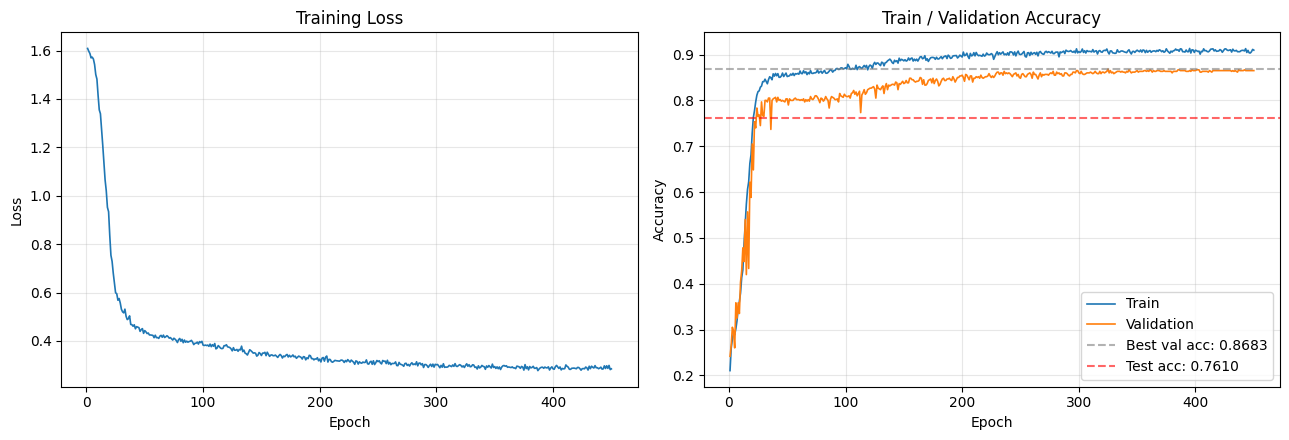

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_range = range(1, len(history["Train loss"]) + 1)

ax1.plot(epochs_range, history["Train loss"], linewidth=1.2)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Training Loss")
ax1.grid(True, alpha=0.3)
ax2.plot(epochs_range, history["Train accu"], label="Train", linewidth=1.2)
ax2.plot(epochs_range, history["Evaluation accu"], label="Validation", linewidth=1.2)
ax2.axhline(y=best_eval_accu, color="gray", linestyle="--", alpha=0.6,
            label=f"Best val acc: {best_eval_accu:.4f}")
ax2.axhline(y=accuracy, color="red", linestyle="--", alpha=0.6,
            label=f"Test acc: {accuracy:.4f}")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.set_title("Train / Validation Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()

## Step 4 — Accuracy Metrics and CSV Submission to Kaggle
At minimum, you **must** report in your submitted notebook:
1. The **number of trainable parameters** (printed in Step 3 above).
2. Your accuracy on the **first half of the test set** (public leaderboard).

**This accuracy must match your public leaderboard score on Kaggle.** If it does not, your leaderboard submission is discarded.

Below we show this evaluation for the logistic regression baseline. Note that the baseline accuracy is close to **random chance (20%)** — you should aim to do much better.

In [ ]:
"""
x_test = np.load('datasets/x_test.npy')        # (2000, 5, 32, 32) — 2000 test groups
x_test_half = x_test[:1000]                     # first half: you have the true labels
y_test_half = np.load('datasets/y_test.npy')    # (1000,) — true labels for the first half only
"""
x_test = np.load(f'{DATASET_DIR}/x_test.npy')
x_test_half = x_test[:1000]
y_test_half = np.load(f'{DATASET_DIR}/y_test.npy')

print(f'Test set: {x_test.shape[0]} groups total')
print(f'Public half: {x_test_half.shape[0]} groups (labels provided)')
print(f'Private half: {x_test.shape[0] - x_test_half.shape[0]} groups (labels hidden)\n')

predictions = clf.predict(x_test_half.reshape(x_test_half.shape[0], -1))
accuracy = accuracy_score(y_test_half, predictions)
print(f'Public test accuracy (should match public leaderboard): {accuracy * 100:.2f}%')

Test set: 2000 groups total
Public half: 1000 groups (labels provided)
Private half: 1000 groups (labels hidden)

Public test accuracy (should match public leaderboard): 20.90%


In [ ]:
# ============================================================
# REQUIRED: Print your model's accuracy on the public test half.
# This number MUST match your public leaderboard score on Kaggle.
# Replace the code below with your own model's predictions.
# ============================================================

# your_predictions = ...  # your model's predictions on x_test_half
# your_accuracy = accuracy_score(y_test_half, your_predictions)
# print(f'Public test accuracy (must match Kaggle public leaderboard): {your_accuracy * 100:.2f}%')
#-----------------------Evaluation
model.eval()
correct = 0
total = 0
for images, labels in public_test_loader:
    images = images.to(device)
    labels = labels.to(device)

    scores = model(images)
    _, prediction = torch.max(scores.data, dim=1)
    correct += (prediction == labels).sum().item()
    total += labels.size(0)

accuracy = correct/total
print(f"Public test accuracy (should match public leaderboard: {accuracy * 100:.2f}%")
print(f"Ratio: {correct}/{total}")



Public test accuracy (should match public leaderboard: 76.10%
Ratio: 761/1000


### Generating the CSV for Kaggle Submission
In order to submit your results to Kaggle you need to provide your predictions in CSV format. The code below shows how to do this for the logistic regression baseline above. You can use the same method for your submission.

Note that you need to submit your result for the **entire test set** of size **2,000**. Your accuracy on the first 1,000 will show on the public leaderboard and the remaining 1,000 are on the private leaderboard that will be revealed when the competition is over. Submit the `predicted_labels.csv` to the Kaggle competition!

In [ ]:
import pandas as pd

model.eval()
all_preds = []

# generate prediction for full test set
with torch.no_grad():
    for images, _ in full_test_loader:
        images = images.to(device)
        scores = model(images)
        preds = scores.argmax(dim=1)
        all_preds.append(preds.cpu().numpy())

all_preds = np.concatenate(all_preds)
print(f"Generated {len(all_preds)} predictions")



def generate_csv_kaggle(y):
    indexes = np.arange(len(y))
    csv_labels = np.concatenate((indexes.reshape(-1, 1), y.reshape(-1, 1)), axis=1)
    df = pd.DataFrame(csv_labels, columns=['Id', 'Category'])
    df['Id'] = df['Id'].astype(str)
    df['Category'] = df['Category'].astype(str)
    df.to_csv('predicted_labels.csv', index=False)


generate_csv_kaggle(all_preds)
print(f'Saved {len(all_preds)} predictions to predicted_labels.csv')

Generated 2000 predictions
Saved 2000 predictions to predicted_labels.csv
